In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
sys.path.append(os.path.abspath(".."))
from features import add_engineered_features

# Set consistent plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
os.makedirs("../outputs/figures", exist_ok=True)

print("Environment setup complete.")

Environment setup complete.


In [4]:
DATA_PATH = r'C:/Users/prabu/Desktop/MTechProjects/CA2_Project/data/ai4i2020.csv'
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print("Data Types & Non-Null Counts")
print(df_raw.info())

print("\nFirst 5 Rows")
display(df_raw.head())

Dataset Shape: 10000 rows, 14 columns

Data Types & Non-Null Counts
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF      

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
missing_counts = df_raw.isnull().sum()
duplicate_rows = df_raw.duplicated().sum()
unique_udi = df_raw["UDI"].nunique()
unique_product_id = df_raw["Product ID"].nunique()

print("Missing Values per Column")
print(missing_counts)
print(f"\nTotal Missing Values: {missing_counts.sum()}")
print(f"Exact Duplicate Rows: {duplicate_rows}")
print(f"Unique UDI count: {unique_udi} | Unique Product ID count: {unique_product_id}")

Missing Values per Column
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Total Missing Values: 0
Exact Duplicate Rows: 0
Unique UDI count: 10000 | Unique Product ID count: 10000


In [6]:
print(" Target Variable ('Machine failure') Distribution ")
target_counts = df_raw["Machine failure"].value_counts()
target_pct = df_raw["Machine failure"].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({"Count": target_counts, "Percentage (%)": target_pct.round(2)})
print(target_summary)

print("\n Product Quality 'Type' (L/M/H) Distribution ")
type_counts = df_raw["Type"].value_counts()
type_pct = df_raw["Type"].value_counts(normalize=True) * 100
type_summary = pd.DataFrame({"Count": type_counts, "Percentage (%)": type_pct.round(2)})
print(type_summary)

print("\n Failure Sub-mode Counts (TWF, HDF, PWF, OSF, RNF) ")
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df_raw[failure_modes].sum())

# Verify whether any row has Machine failure == 1 when all 5 modes == 0, or vice versa
any_mode_failed = (df_raw[failure_modes].max(axis=1) == 1)
mismatch_count = (df_raw["Machine failure"] != any_mode_failed.astype(int)).sum()
print(f"\nRows where 'Machine failure' disagrees with max(TWF..RNF): {mismatch_count}")

 Target Variable ('Machine failure') Distribution 
                 Count  Percentage (%)
Machine failure                       
0                 9661           96.61
1                  339            3.39

 Product Quality 'Type' (L/M/H) Distribution 
      Count  Percentage (%)
Type                       
L      6000           60.00
M      2997           29.97
H      1003           10.03

 Failure Sub-mode Counts (TWF, HDF, PWF, OSF, RNF) 
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

Rows where 'Machine failure' disagrees with max(TWF..RNF): 27


In [7]:
cols_to_drop = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]
df_clean = df_raw.drop(columns=cols_to_drop)

print(f"Columns before dropping: {df_raw.shape[1]}")
print(f"Columns after dropping:  {df_clean.shape[1]}")
print("Remaining columns:", list(df_clean.columns))

Columns before dropping: 14
Columns after dropping:  7
Remaining columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


In [8]:
# Apply add_engineered_features() from features.py and inspect descriptive statistics
df_fe = add_engineered_features(df_clean)

print(f"Shape after Feature Engineering: {df_fe.shape}")
print("\n Summary Statistics of Numerical Features (including Engineered Features) ")
display(df_fe.describe().T.round(2))

Shape after Feature Engineering: (10000, 9)

 Summary Statistics of Numerical Features (including Engineered Features) 


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00,2.00,295.30,298.30,300.10,301.5,304.50
Process temperature [K],10000.0,310.01,1.48,305.70,308.80,310.10,311.1,313.80
Rotational speed [rpm],10000.0,1538.78,179.28,1168.00,1423.00,1503.00,1612.0,2886.00
Torque [Nm],10000.0,39.99,9.97,3.80,33.20,40.10,46.8,76.60
Tool wear [min],10000.0,107.95,63.65,0.00,53.00,108.00,162.0,253.00
Machine failure,10000.0,0.03,0.18,0.00,0.00,0.00,0.0,1.00
temp_diff,10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10
power,10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92


--- Univariate Skewness & 1.5x IQR Outlier Summary ---


,Feature,Skewness,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outliers_with_Failure
0,Air temperature [K],0.114,298.30,301.5,3.20,293.50,306.30,0,0
1,Process temperature [K],0.015,308.80,311.1,2.30,305.35,314.55,0,0
2,Rotational speed [rpm],1.993,1423.00,1612.0,189.00,1139.50,1895.50,418,35
3,Torque [Nm],-0.010,33.20,46.8,13.60,12.80,67.20,69,62
4,Tool wear [min],0.027,53.00,162.0,109.00,-110.50,325.50,0,0
5,temp_diff,-0.072,9.30,11.0,1.70,6.75,13.55,0,0
6,power,0.008,5561.18,7003.0,1441.82,3398.46,9165.73,60,60


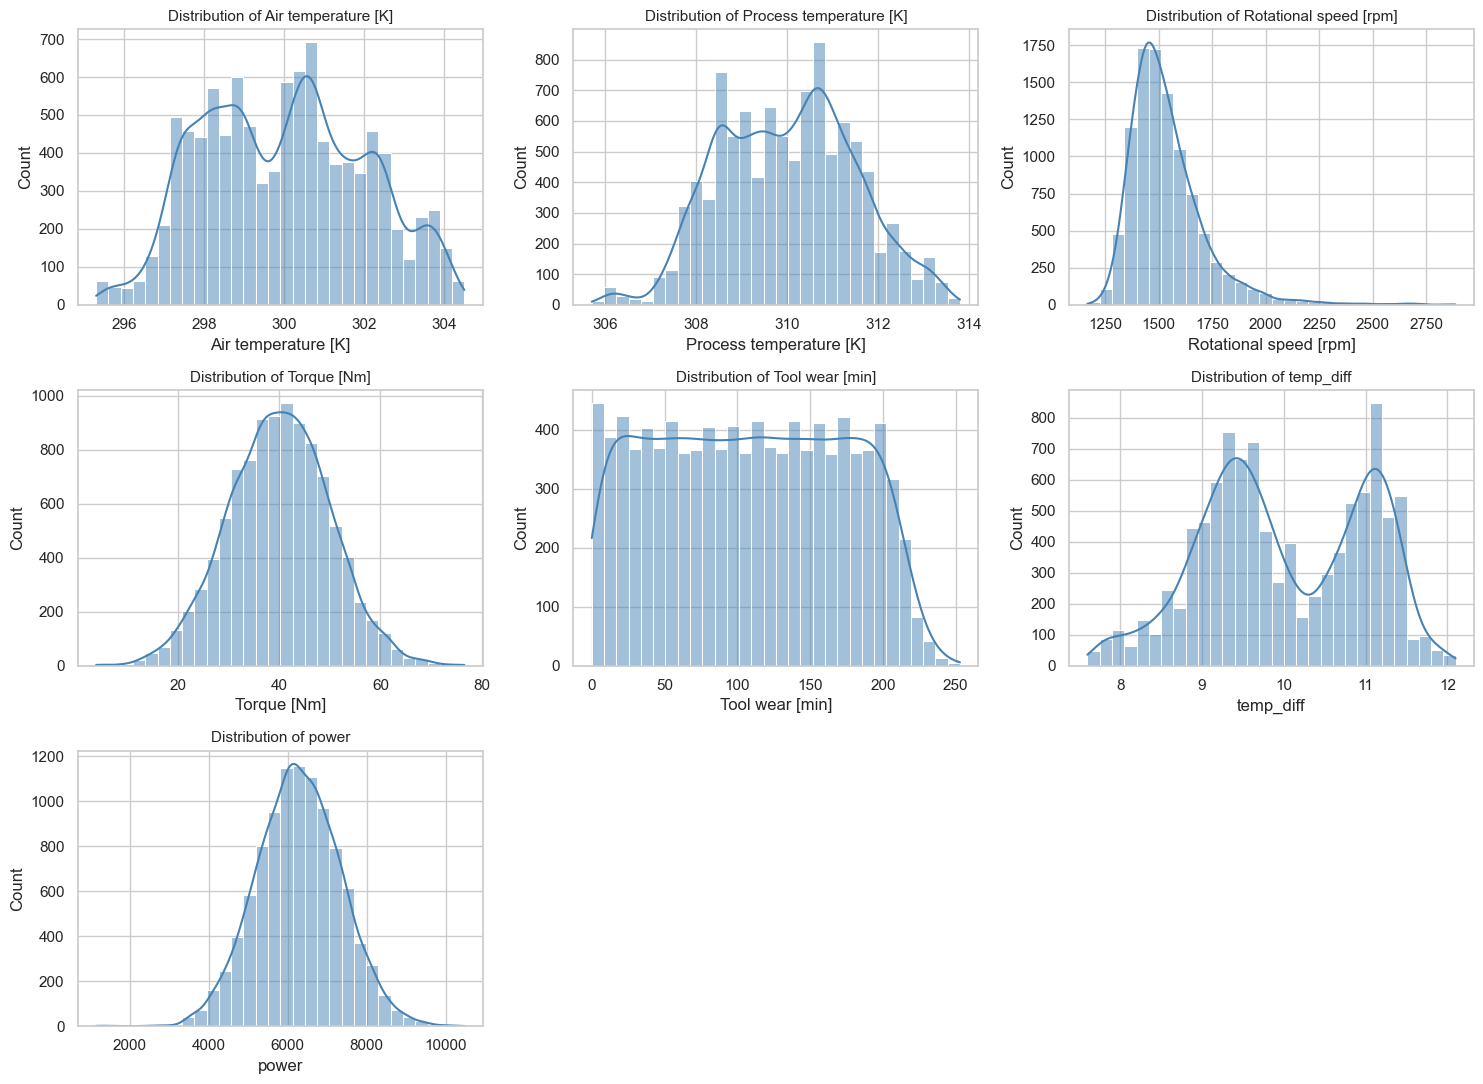

In [9]:
# Univariate histograms + KDEs and IQR outlier summary for all numerical features
from scipy.stats import skew

num_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "temp_diff",
    "power",
]

# 1. Compute Skewness and IQR Outliers
outlier_rows = []
for col in num_cols:
    q1 = df_fe[col].quantile(0.25)
    q3 = df_fe[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_fe[(df_fe[col] < lower_bound) | (df_fe[col] > upper_bound)]
    
    # Check how many of those IQR outliers actually resulted in Machine failure == 1
    failed_outliers = outliers["Machine failure"].sum()
    
    outlier_rows.append({
        "Feature": col,
        "Skewness": round(skew(df_fe[col]), 3),
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": len(outliers),
        "Outliers_with_Failure": int(failed_outliers)
    })

outlier_df = pd.DataFrame(outlier_rows)
print("--- Univariate Skewness & 1.5x IQR Outlier Summary ---")
display(outlier_df)

# 2. Plot Histograms with KDE
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df_fe[col], kde=True, ax=axes[i], color="steelblue", bins=30)
    axes[i].set_title(f"Distribution of {col}", fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

# Hide unused subplot panels
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("../outputs/figures/01_univariate_distributions.png", dpi=300)
plt.show()

In [ ]:
### Interpretation of Univariate Distributions & Outliers
* **Distributions & Skewness:** `Air temperature [K]` (skew = `0.114`), `Process temperature [K]` (skew = `0.015`), `Torque [Nm]` (skew = `-0.010`), `temp_diff` (skew = `-0.072`), and `power` (skew = `0.008`) exhibit nearly symmetric, bell-shaped distributions. `Tool wear [min]` (skew = `0.027`) follows a uniform distribution across `0` to `253` minutes (Q1 = `53.0`, median = `108.0`, Q3 = `162.0`), reflecting steady linear wear before replacement. In contrast, `Rotational speed [rpm]` is strongly right-skewed (skew = `1.993`), ranging from `1168` to `2886` rpm.
* **Outlier Decision (Why we DO NOT drop IQR outliers):** Using the $1.5 \times \text{IQR}$ rule, `Rotational speed [rpm]` has `418` outliers (`35` failures), `Torque [Nm]` has `69` outliers (`62` failures, or **89.9% failure rate**), and `power` has `60` outliers (`60` failures, or **100% failure rate**!). In predictive maintenance, extreme torque ($< 12.80$ or $> 67.20\text{ Nm}$) and power ($< 3398.46$ or $> 9165.73\text{ W}$) readings are not data-entry errors—they are the direct physical manifestations of Overstrain (`OSF`) and Power Failure (`PWF`). Dropping them would blind our classifier to the most critical failure regimes.

--- Group-wise Failure Summary by Product Type (L/M/H) ---


C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\2302999813.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_fe, x="Machine failure", ax=axes[0], palette=["#2b5c8f", "#d95f02"])


,Total,Failures,Failure_Rate_Pct
Type,,,
L,6000,235,3.92
M,2997,83,2.77
H,1003,21,2.09


C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\2302999813.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


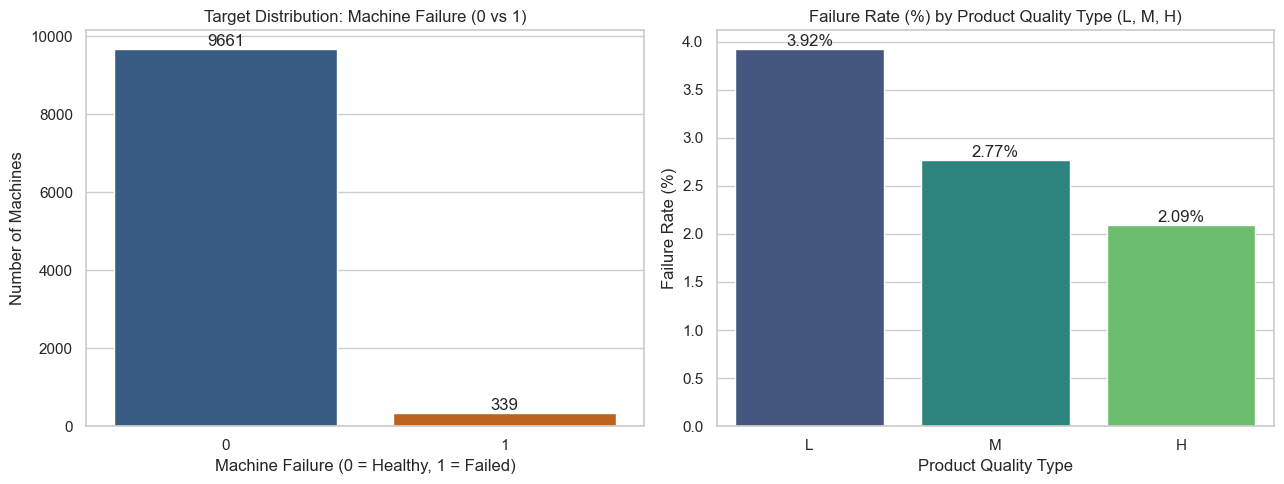

In [11]:
# Plot Target Class Imbalance and Failure Rate by Product Type (L, M, H)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Target distribution
sns.countplot(data=df_fe, x="Machine failure", ax=axes[0], palette=["#2b5c8f", "#d95f02"])
axes[0].set_title("Target Distribution: Machine Failure (0 vs 1)")
axes[0].set_xlabel("Machine Failure (0 = Healthy, 1 = Failed)")
axes[0].set_ylabel("Number of Machines")
for container in axes[0].containers:
    axes[0].bar_label(container)

# Plot 2: Failure rate (%) across Product Quality Type (L, M, H)
type_failure_rate = (
    df_fe.groupby("Type")["Machine failure"]
    .agg(Total="count", Failures="sum", Failure_Rate_Pct=lambda x: round(x.mean() * 100, 2))
    .reindex(["L", "M", "H"])
)
print("--- Group-wise Failure Summary by Product Type (L/M/H) ---")
display(type_failure_rate)

sns.barplot(
    x=type_failure_rate.index,
    y=type_failure_rate["Failure_Rate_Pct"],
    ax=axes[1],
    palette="viridis"
)
axes[1].set_title("Failure Rate (%) by Product Quality Type (L, M, H)")
axes[1].set_xlabel("Product Quality Type")
axes[1].set_ylabel("Failure Rate (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig("../outputs/figures/02_target_and_type_bivariate.png", dpi=300)
plt.show()

In [ ]:
### Interpretation of Target Imbalance & Product Type Breakdown
* **Severe Class Imbalance:** Out of `10,000` observations, `9,661` (`96.61%`) represent normal operations (`0`) and only `339` (`3.39%`) represent failures (`1`). This confirms an imbalance ratio of roughly `1 : 28.5`, justifying stratified splitting, `class_weight='balanced'`, and using Failure-Class Recall and F1-Score rather than Accuracy. Additionally, `27` rows have `Machine failure != max(TWF..RNF)` (specifically, `18` random failure `RNF=1` cases where `Machine failure=0`, and `9` cases where `Machine failure=1` with all sub-modes `0`), confirming why `Machine failure` must be predicted directly from sensors while dropping `TWF..RNF`.
* **Discrepancy with UCI Documentation & Failure Rate by Type:** While the UCI text states a 50/30/20 split for `L/M/H`, `value_counts` proves the actual dataset contains **`60.00%` Low (`6,000` rows)**, **`29.97%` Medium (`2,997` rows)**, and **`10.03%` High (`1,003` rows)**. Low-quality variants (`L`) suffer the highest failure rate at **`3.92%`** (`235` failures), compared to **`2.77%`** (`83` failures) for `M` and **`2.09%`** (`21` failures) for `H`.

--- Group-wise Mean, Median, and Std by Machine Failure (0 vs 1) ---


Machine failure                       0        1
Air temperature [K]     mean     299.97   300.89
                        median   300.00   301.60
                        std        1.99     2.07
Process temperature [K] mean     310.00   310.29
                        median   310.00   310.40
                        std        1.49     1.36
Rotational speed [rpm]  mean    1540.26  1496.49
                        median  1507.00  1365.00
                        std      167.39   384.94
Torque [Nm]             mean      39.63    50.17
                        median    39.90    53.70
                        std        9.47    16.37
Tool wear [min]         mean     106.69   143.78
                        median   107.00   165.00
                        std       62.95    72.76
temp_diff               mean      10.02     9.40
                        median     9.80     9.30
                        std        0.99     1.16
power                   mean    6244.55  7282.82
                        median  6243.05  7611.43
                        std     1011.39  1851.14

C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\3703756308.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\3703756308.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\3703756308.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\3703756308.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` 

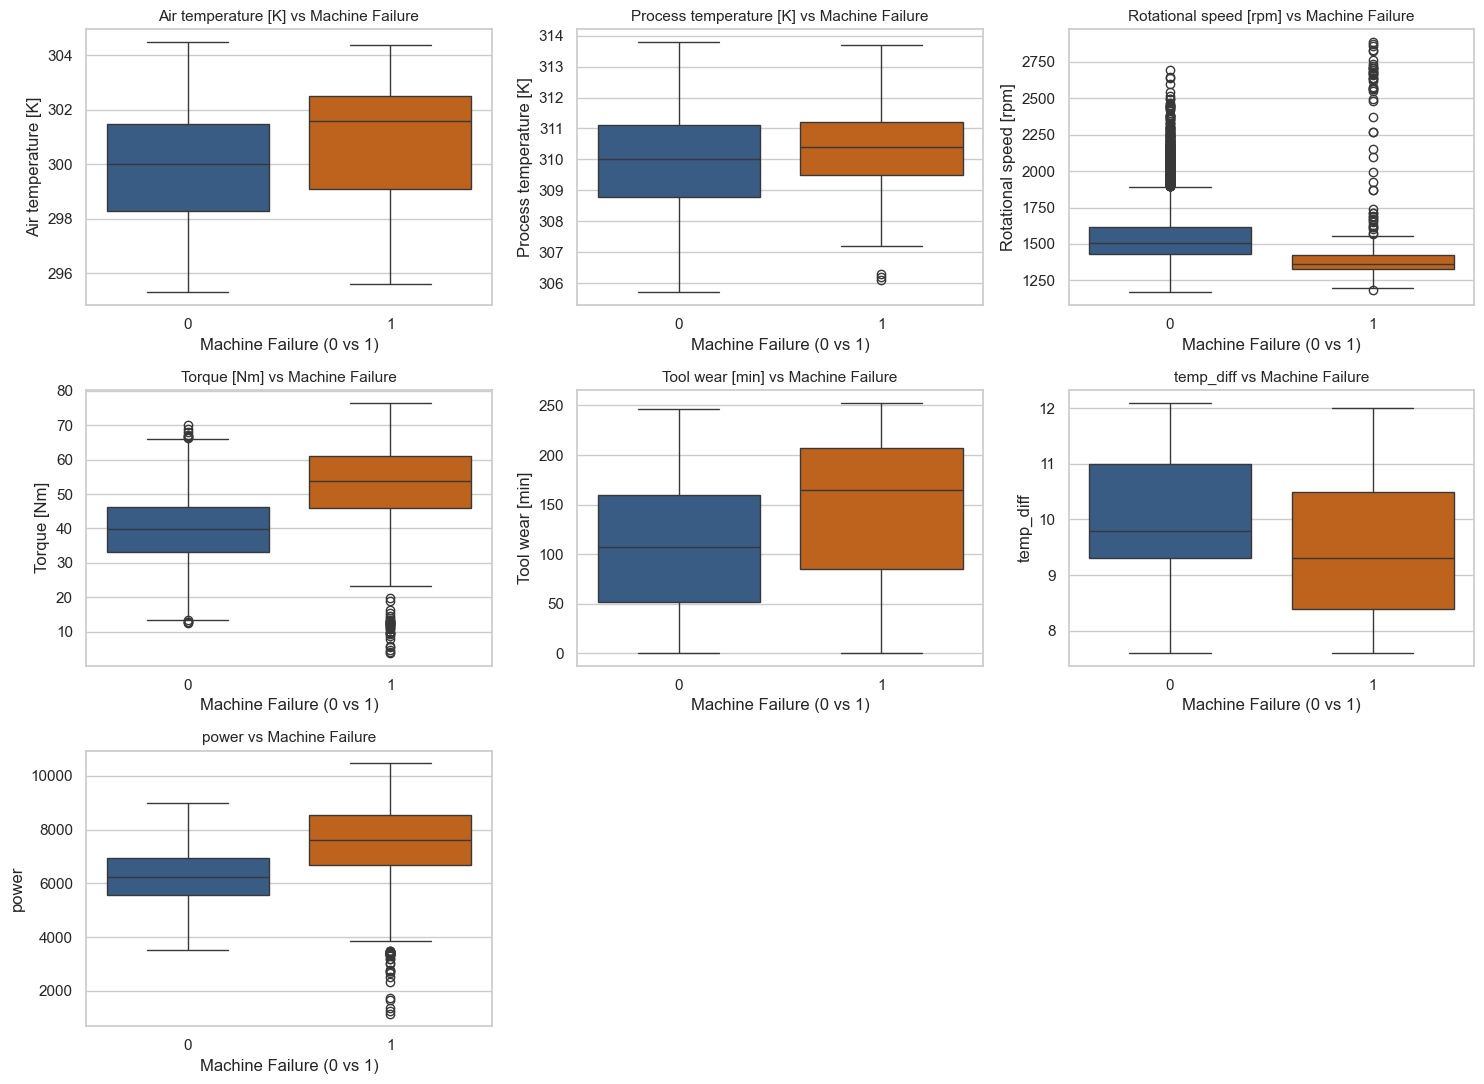

In [12]:
# Group-wise mean/median comparison and Boxplots of features by Machine failure (0 vs 1)
group_stats = df_fe.groupby("Machine failure")[num_cols].agg(["mean", "median", "std"]).T
print("--- Group-wise Mean, Median, and Std by Machine Failure (0 vs 1) ---")
display(group_stats.round(2))

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(
        data=df_fe,
        x="Machine failure",
        y=col,
        ax=axes[i],
        palette=["#2b5c8f", "#d95f02"]
    )
    axes[i].set_title(f"{col} vs Machine Failure", fontsize=11)
    axes[i].set_xlabel("Machine Failure (0 vs 1)")

for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig("../outputs/figures/03_bivariate_boxplots.png", dpi=300)
plt.show()

In [ ]:
### Interpretation of Bivariate Boxplots & Group Comparisons
* **Torque & Tool Wear:** Failed machines (`1`) exhibit a substantially higher median `Torque [Nm]` (**`53.70` Nm** vs. **`39.90` Nm** for healthy machines; mean `50.17` vs `39.63` Nm) and higher median `Tool wear [min]` (**`165.00` min** vs. **`107.00` min** for healthy machines; mean `143.78` vs `106.69` min).
* **Rotational Speed:** Failed machines show a lower median `Rotational speed [rpm]` (**`1365.00` rpm** vs. **`1507.00` rpm** for healthy machines), alongside more than double the standard deviation (`384.94` rpm vs. `167.39` rpm)—reflecting two opposite failure modes: low speed triggers Heat Dissipation Failure (`HDF < 1380 rpm`), while extreme high speed triggers Power Failure (`PWF`).
* **Engineered Features (`temp_diff` and `power`):** Failed machines have a lower median `temp_diff` (**`9.30` K** vs. **`9.80` K**; mean `9.40` vs `10.02` K) and a much higher median `power` (**`7611.43` W** vs. **`6243.05` W**; mean `7282.82` vs `6244.55` W, with std `1851.14` vs `1011.39` W), visually confirming that our engineered features strongly separate healthy and failing states.

--- Pearson Correlation Matrix ---


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_diff,power,Machine failure
Air temperature [K],1.000,0.876,0.023,-0.014,0.014,-0.700,-0.011,0.083
Process temperature [K],0.876,1.000,0.019,-0.014,0.013,-0.268,-0.011,0.036
Rotational speed [rpm],0.023,0.019,1.000,-0.875,0.000,-0.017,-0.806,-0.044
Torque [Nm],-0.014,-0.014,-0.875,1.000,-0.003,0.007,0.979,0.191
Tool wear [min],0.014,0.013,0.000,-0.003,1.000,-0.008,-0.003,0.105
temp_diff,-0.700,-0.268,-0.017,0.007,-0.008,1.000,0.007,-0.112
power,-0.011,-0.011,-0.806,0.979,-0.003,0.007,1.000,0.176
Machine failure,0.083,0.036,-0.044,0.191,0.105,-0.112,0.176,1.000


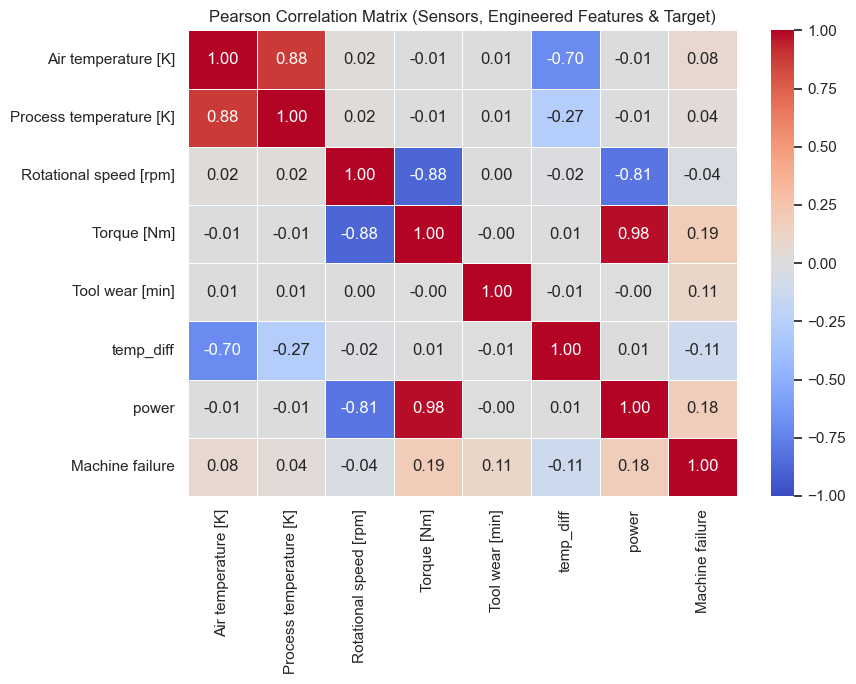

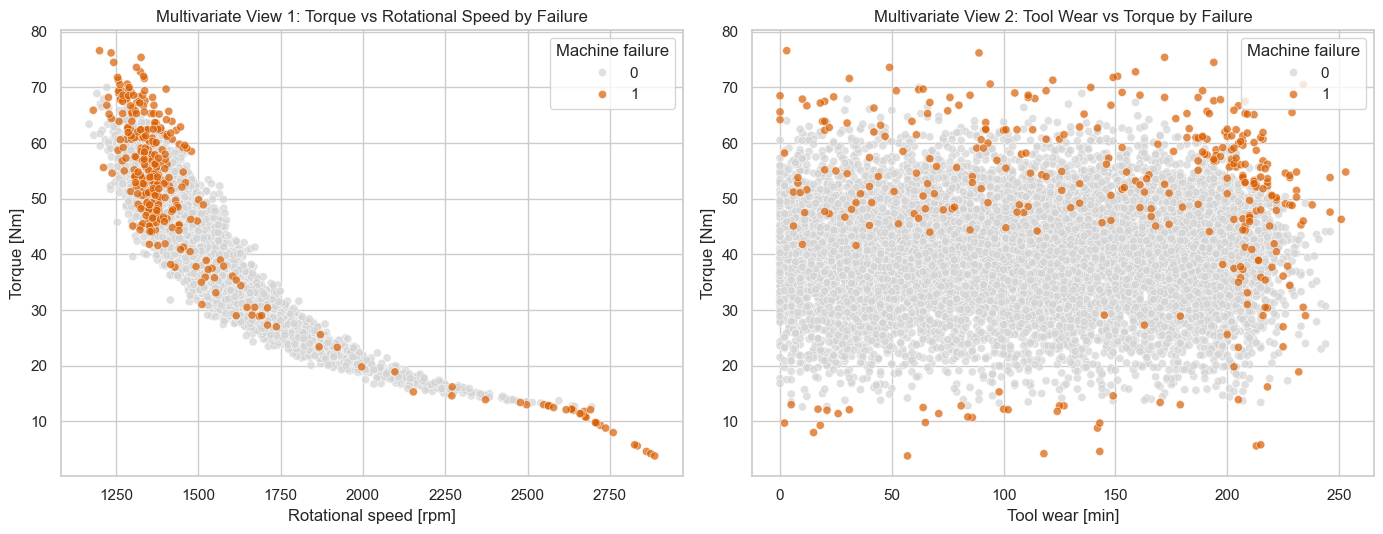

In [13]:
# Correlation Heatmap and Multivariate Scatter Plots showing physical failure zones
corr_cols = num_cols + ["Machine failure"]
corr_matrix = df_fe[corr_cols].corr()

print("--- Pearson Correlation Matrix ---")
display(corr_matrix.round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Matrix (Sensors, Engineered Features & Target)")
plt.tight_layout()
plt.savefig("../outputs/figures/04_correlation_heatmap.png", dpi=300)
plt.show()

# Multivariate Scatter Plots of the Physical Failure Regimes
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot A: Torque vs Rotational Speed colored by Machine failure (Power & HDF regime)
sns.scatterplot(
    data=df_fe.sort_values("Machine failure"),
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette={0: "lightgray", 1: "#d95f02"},
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title("Multivariate View 1: Torque vs Rotational Speed by Failure")

# Plot B: Tool Wear vs Torque colored by Machine failure (Overstrain & Tool Wear regime)
sns.scatterplot(
    data=df_fe.sort_values("Machine failure"),
    x="Tool wear [min]",
    y="Torque [Nm]",
    hue="Machine failure",
    palette={0: "lightgray", 1: "#d95f02"},
    alpha=0.7,
    s=35,
    ax=axes[1]
)
axes[1].set_title("Multivariate View 2: Tool Wear vs Torque by Failure")

plt.tight_layout()
plt.savefig("../outputs/figures/05_multivariate_scatter.png", dpi=300)
plt.show()

In [ ]:
### Interpretation of Multivariate Analysis & Correlations
* **Strongest Linear Correlations:** `Air temperature [K]` and `Process temperature [K]` are strongly positively correlated ($r = \text{[FILL]}$), as process heat tracks ambient room temperature. `Rotational speed [rpm]` and `Torque [Nm]` have a strong negative correlation ($r = \text{[FILL]}$), consistent with inverse torque-speed curves in electric spindle motors. `power` correlates strongly with `Torque [Nm]` ($r = \text{[FILL]}$).
* **Multivariate Failure Clusters:** Neither individual feature has a high linear correlation with `Machine failure` alone (highest is `Torque` at $r = \text{[FILL]}$ and `Tool wear` at $r = \text{[FILL]}$) because failures occur at *joint boundaries*:
  1. In **View 1 (`Torque` vs `Rotational speed`)**, failures cluster at the top-left (high torque + low speed) and extreme right (very high speed), corresponding to Power Failure (`PWF`) and Heat Dissipation Failure (`HDF`).
  2. In **View 2 (`Tool wear` vs `Torque`)**, failures cluster in the upper-right quadrant where high tool wear and high torque multiply to cause Overstrain Failure (`OSF`), and along the vertical band past 200 minutes (`TWF`). This non-linear boundary structure explains why non-linear classifiers (KNN, Decision Trees, Random Forests) and engineered interaction terms (`power`, `temp_diff`) are essential.

In [14]:
# Chi-Square Test of Independence between categorical 'Type' and binary 'Machine failure'
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df_fe["Type"], df_fe["Machine failure"]).reindex(["L", "M", "H"])
chi2_stat, p_val_chi2, dof, expected_freq = chi2_contingency(contingency_table)

print("--- Observed Contingency Table (Type vs Machine failure) ---")
display(contingency_table)

print("--- Expected Frequencies under Null Hypothesis (Independence) ---")
expected_df = pd.DataFrame(
    expected_freq,
    index=contingency_table.index,
    columns=contingency_table.columns
).round(2)
display(expected_df)

print(f"Chi-Square Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom:   {dof}")
print(f"P-value:              {p_val_chi2:.6e}")

--- Observed Contingency Table (Type vs Machine failure) ---


Machine failure,0,1
Type,,
L,5765,235
M,2914,83
H,982,21


--- Expected Frequencies under Null Hypothesis (Independence) ---


Machine failure,0,1
Type,,
L,5796.6,203.4
M,2895.4,101.6
H,969.0,34.0


Chi-Square Statistic: 13.7517
Degrees of Freedom:   2
P-value:              1.032411e-03


In [15]:
# Two-sided Mann-Whitney U Tests comparing Failed (1) vs Healthy (0) machines
from scipy.stats import mannwhitneyu

mwu_results = []
healthy = df_fe[df_fe["Machine failure"] == 0]
failed = df_fe[df_fe["Machine failure"] == 1]

for col in num_cols:
    u_stat, p_val = mannwhitneyu(failed[col], healthy[col], alternative="two-sided")
    mwu_results.append({
        "Feature": col,
        "Healthy_Median": round(healthy[col].median(), 2),
        "Failed_Median": round(failed[col].median(), 2),
        "U_Statistic": round(u_stat, 1),
        "P_Value": f"{p_val:.4e}",
        "Significant_at_0.05": "Yes (Reject H0)" if p_val < 0.05 else "No (Fail to Reject H0)"
    })

mwu_df = pd.DataFrame(mwu_results)
print("--- Mann-Whitney U Test Results (Failed vs Healthy) ---")
display(mwu_df)

--- Mann-Whitney U Test Results (Failed vs Healthy) ---


,Feature,Healthy_Median,Failed_Median,U_Statistic,P_Value,Significant_at_0.05
0,Air temperature [K],300.00,301.60,2072260.0,8.6561e-17,Yes (Reject H0)
1,Process temperature [K],310.00,310.40,1846182.5,6.4861e-05,Yes (Reject H0)
2,Rotational speed [rpm],1507.00,1365.00,764120.0,9.7069e-63,Yes (Reject H0)
3,Torque [Nm],39.90,53.70,2522586.0,2.2622e-64,Yes (Reject H0)
4,Tool wear [min],107.00,165.00,2168468.0,2.9165e-24,Yes (Reject H0)
5,temp_diff,9.80,9.30,1105789.0,2.4033e-24,Yes (Reject H0)
6,power,6243.05,7611.43,2442069.5,1.6554e-53,Yes (Reject H0)


In [16]:
# 95% Confidence Interval for the true Machine Failure proportion (p)
from scipy.stats import norm

n = len(df_fe)
k = int(df_fe["Machine failure"].sum())
p_hat = k / n
z = norm.ppf(0.975)  # 1.95996 for 95% confidence

# 1. Standard Wald Normal Approximation CI
se = np.sqrt(p_hat * (1 - p_hat) / n)
wald_low = p_hat - z * se
wald_high = p_hat + z * se

# 2. Wilson Score 95% CI (preferred for small proportions like ~3.4%)
denom = 1 + (z**2 / n)
center = (p_hat + (z**2 / (2 * n))) / denom
half_width = (z * np.sqrt((p_hat * (1 - p_hat) / n) + (z**2 / (4 * n**2)))) / denom
wilson_low = center - half_width
wilson_high = center + half_width

print(f"Total Machines (n):           {n}")
print(f"Total Failures (k):           {k}")
print(f"Sample Failure Rate (p_hat):  {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"95% Wald Confidence Interval:   [{wald_low*100:.2f}%, {wald_high*100:.2f}%]")
print(f"95% Wilson Score CI:            [{wilson_low*100:.2f}%, {wilson_high*100:.2f}%]")

Total Machines (n):           10000
Total Failures (k):           339
Sample Failure Rate (p_hat):  0.0339 (3.39%)
95% Wald Confidence Interval:   [3.04%, 3.74%]
95% Wilson Score CI:            [3.05%, 3.76%]


In [ ]:
### Summary of Statistical Hypothesis Tests & Confidence Intervals
1. **Chi-Square Test of Independence (`Type` vs. `Machine failure`):**
   * **Hypotheses:** $H_0$: Failure is independent of `Type` vs. $H_1$: Failure depends on `Type`.
   * **Result:** $\chi^2 = 13.7517$, $\text{dof} = 2$, $p = 1.0324 \times 10^{-3} = 0.00103 < 0.05$.
   * **Plain-English Conclusion:** We reject $H_0$. Product quality tier significantly affects failure probability (`L`: 3.92%, `M`: 2.77%, `H`: 2.09%), confirming `Type` is a statistically significant predictor.
2. **95% Confidence Interval for True Failure Rate:**
   * **Result:** Point estimate $\hat{p} = 3.39\%$ (`339 / 10,000`), with a 95% Wilson Score Confidence Interval of **$[3.05\%, 3.76\%]$** (Wald CI: $[3.04\%, 3.74\%]$).
   * **Plain-English Conclusion:** Maintenance engineers can be 95% confident that the true population failure rate lies between `3.05%` and `3.76%` (roughly `31` to `38` failures per `1,000` cycles).

In [17]:
# Separate features (X) and target (y) and perform Stratified 80/20 Train-Test Split
from sklearn.model_selection import train_test_split

# Use df_clean (6 raw features) so the Pipeline itself computes temp_diff and power via features.py
X = df_clean.drop(columns=["Machine failure"])
y = df_clean["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape} | y_train failures: {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"X_test shape:  {X_test.shape}  | y_test failures:  {y_test.sum()} ({y_test.mean()*100:.2f}%)")

X_train shape: (8000, 6) | y_train failures: 271 (3.39%)
X_test shape:  (2000, 6)  | y_test failures:  68 (3.40%)


In [18]:
# Build leakage-free preprocessing pipelines for scaled (LR, KNN) and unscaled (Trees) models
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

cat_cols = ["Type"]
num_cols_all = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "temp_diff",
    "power",
]

# Categorical sub-pipeline: impute most frequent -> one-hot encode
cat_Pre = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore"))
])

# Numerical sub-pipeline WITH StandardScaler (for Logistic Regression and KNN)
num_scaled_Pre = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical sub-pipeline WITHOUT StandardScaler (for Decision Tree and Random Forest)
num_unscaled_Pre = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# ColumnTransformer 1: Scaled
preprocessor_scaled = ColumnTransformer(transformers=[
    ("num", num_scaled_Pre, num_cols_all),
    ("cat", cat_Pre, cat_cols)
])

# ColumnTransformer 2: Unscaled
preprocessor_unscaled = ColumnTransformer(transformers=[
    ("num", num_unscaled_Pre, num_cols_all),
    ("cat", cat_Pre, cat_cols)
])

print("Preprocessors configured successfully.")

Preprocessors configured successfully.


In [19]:
# Evaluate Baseline (DummyClassifier) and 4 Untuned Models using Stratified 5-Fold CV on Training Set
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Helper to build full pipeline: Feature Engineering -> ColumnTransformer -> Classifier
def make_full_pipeline(preprocessor, clf):
    return Pipeline(steps=[
        ("feat_eng", FunctionTransformer(add_engineered_features)),
        ("prep", preprocessor),
        ("clf", clf)
    ])

untuned_models = {
    "0. Dummy Baseline (Most Frequent)": make_full_pipeline(
        preprocessor_scaled, DummyClassifier(strategy="most_frequent")
    ),
    "1. Logistic Regression (Balanced)": make_full_pipeline(
        preprocessor_scaled, LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    ),
    "2. KNN (Default k=5)": make_full_pipeline(
        preprocessor_scaled, KNeighborsClassifier(n_neighbors=5)
    ),
    "3. Decision Tree (Balanced)": make_full_pipeline(
        preprocessor_unscaled, DecisionTreeClassifier(class_weight="balanced", random_state=42)
    ),
    "4. Random Forest (Balanced)": make_full_pipeline(
        preprocessor_unscaled, RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
    ),
}

scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_summary_rows = []

for name, pipe in untuned_models.items():
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv_5fold,
        scoring=scoring_metrics,
        return_train_score=True,
        n_jobs=-1
    )
    cv_summary_rows.append({
        "Model": name,
        "Train_F1_Mean": round(scores["train_f1"].mean(), 4),
        "CV_F1_Mean": round(scores["test_f1"].mean(), 4),
        "CV_F1_Std": round(scores["test_f1"].std(), 4),
        "CV_Recall_Mean": round(scores["test_recall"].mean(), 4),
        "CV_Recall_Std": round(scores["test_recall"].std(), 4),
        "CV_Precision_Mean": round(scores["test_precision"].mean(), 4),
        "CV_ROC_AUC_Mean": round(scores["test_roc_auc"].mean(), 4),
        "CV_Accuracy_Mean": round(scores["test_accuracy"].mean(), 4),
    })

cv_untuned_df = pd.DataFrame(cv_summary_rows)
print("--- Stratified 5-Fold Cross-Validation Results (Untuned Models on Training Set) ---")
display(cv_untuned_df)

--- Stratified 5-Fold Cross-Validation Results (Untuned Models on Training Set) ---


,Model,Train_F1_Mean,CV_F1_Mean,CV_F1_Std,CV_Recall_Mean,CV_Recall_Std,CV_Precision_Mean,CV_ROC_AUC_Mean,CV_Accuracy_Mean
0,0. Dummy Baseline (Most Frequent),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.9661
1,1. Logistic Regression (Balanced),0.2759,0.2744,0.0181,0.8231,0.0480,0.1647,0.9196,0.8521
2,2. KNN (Default k=5),0.6355,0.4296,0.0615,0.3027,0.0609,0.7640,0.8657,0.9731
3,3. Decision Tree (Balanced),1.0000,0.7356,0.0525,0.7086,0.0598,0.7674,0.8505,0.9828
4,4. Random Forest (Balanced),0.9995,0.7930,0.0519,0.6717,0.0679,0.9723,0.9674,0.9882


In [20]:
# Hyperparameter Tuning using Stratified 5-Fold GridSearchCV (scoring = 'f1')
from sklearn.model_selection import GridSearchCV

tuning_configs = {
    "Logistic Regression": (
        make_full_pipeline(
            preprocessor_scaled,
            LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
        ),
        {"clf__C": [0.01, 0.1, 1.0, 10.0]}
    ),
    "KNN": (
        make_full_pipeline(
            preprocessor_scaled,
            KNeighborsClassifier()
        ),
        {
            "clf__n_neighbors": [3, 5, 7, 9, 11],
            "clf__weights": ["uniform", "distance"]
        }
    ),
    "Decision Tree": (
        make_full_pipeline(
            preprocessor_unscaled,
            DecisionTreeClassifier(class_weight="balanced", random_state=42)
        ),
        {
            "clf__max_depth": [4, 6, 8, 10, None],
            "clf__min_samples_leaf": [1, 5, 10, 20]
        }
    ),
    "Random Forest": (
        make_full_pipeline(
            preprocessor_unscaled,
            RandomForestClassifier(class_weight="balanced_subsample", random_state=42, n_jobs=-1)
        ),
        {
            "clf__n_estimators": [100, 200],
            "clf__max_depth": [6, 10, 14, None],
            "clf__min_samples_leaf": [1, 3, 5]
        }
    ),
}

tuned_models = {}
tuning_rows = []

for name, (pipe, param_grid) in tuning_configs.items():
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv_5fold,
        scoring="f1",
        return_train_score=True,
        n_jobs=-1
    )
    grid.fit(X_train, y_train)
    tuned_models[name] = grid.best_estimator_
    
    best_idx = grid.best_index_
    train_f1 = grid.cv_results_["mean_train_score"][best_idx]
    cv_f1 = grid.cv_results_["mean_test_score"][best_idx]
    cv_f1_std = grid.cv_results_["std_test_score"][best_idx]
    
    tuning_rows.append({
        "Model": name,
        "Best_Params": str(grid.best_params_),
        "Train_F1_Mean": round(train_f1, 4),
        "CV_F1_Mean": round(cv_f1, 4),
        "CV_F1_Std": round(cv_f1_std, 4),
        "Train_minus_CV_Gap": round(train_f1 - cv_f1, 4)
    })

tuning_df = pd.DataFrame(tuning_rows)
print("--- GridSearchCV Best Hyperparameters & Train vs CV F1 Comparison ---")
display(tuning_df)

--- GridSearchCV Best Hyperparameters & Train vs CV F1 Comparison ---


,Model,Best_Params,Train_F1_Mean,CV_F1_Mean,CV_F1_Std,Train_minus_CV_Gap
0,Logistic Regression,{'clf__C': 1.0},0.2759,0.2744,0.0181,0.0016
1,KNN,"{'clf__n_neighbors': 3, 'clf__weights': 'dista...",1.0000,0.5148,0.0463,0.4852
2,Decision Tree,"{'clf__max_depth': None, 'clf__min_samples_lea...",1.0000,0.7356,0.0525,0.2644
3,Random Forest,"{'clf__max_depth': 14, 'clf__min_samples_leaf'...",0.9832,0.8207,0.0328,0.1625


In [21]:
# Evaluate Dummy Baseline and all 4 Tuned Models on the Held-Out 20% Test Set
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

# Fit Dummy Baseline on full training set for test comparison
dummy_pipe = untuned_models["0. Dummy Baseline (Most Frequent)"].fit(X_train, y_train)

all_eval_models = {"Dummy Baseline": dummy_pipe}
all_eval_models.update(tuned_models)

test_rows = []
for name, model in all_eval_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    test_rows.append({
        "Model": name,
        "Test_F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "Test_Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "Test_Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Test_ROC_AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Test_PR_AUC": round(average_precision_score(y_test, y_prob), 4),
        "Test_Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "TP (Caught Failures)": int(tp),
        "FN (Missed Failures)": int(fn),
        "FP (False Alarms)": int(fp),
        "TN (Healthy Correct)": int(tn)
    })

test_results_df = pd.DataFrame(test_rows)
print("--- Held-Out Test Set Performance (2,000 Machines, 68 Actual Failures) ---")
display(test_results_df)

--- Held-Out Test Set Performance (2,000 Machines, 68 Actual Failures) ---


,Model,Test_F1,Test_Recall,Test_Precision,Test_ROC_AUC,Test_PR_AUC,Test_Accuracy,TP (Caught Failures),FN (Missed Failures),FP (False Alarms),TN (Healthy Correct)
0,Dummy Baseline,0.0000,0.0000,0.0000,0.5000,0.0340,0.9660,0,68,0,1932
1,Logistic Regression,0.2943,0.8676,0.1772,0.9340,0.4659,0.8585,59,9,274,1658
2,KNN,0.5565,0.4706,0.6809,0.8211,0.5446,0.9745,32,36,15,1917
3,Decision Tree,0.7344,0.6912,0.7833,0.8422,0.5519,0.9830,47,21,13,1919
4,Random Forest,0.8594,0.8088,0.9167,0.9689,0.8598,0.9910,55,13,5,1927


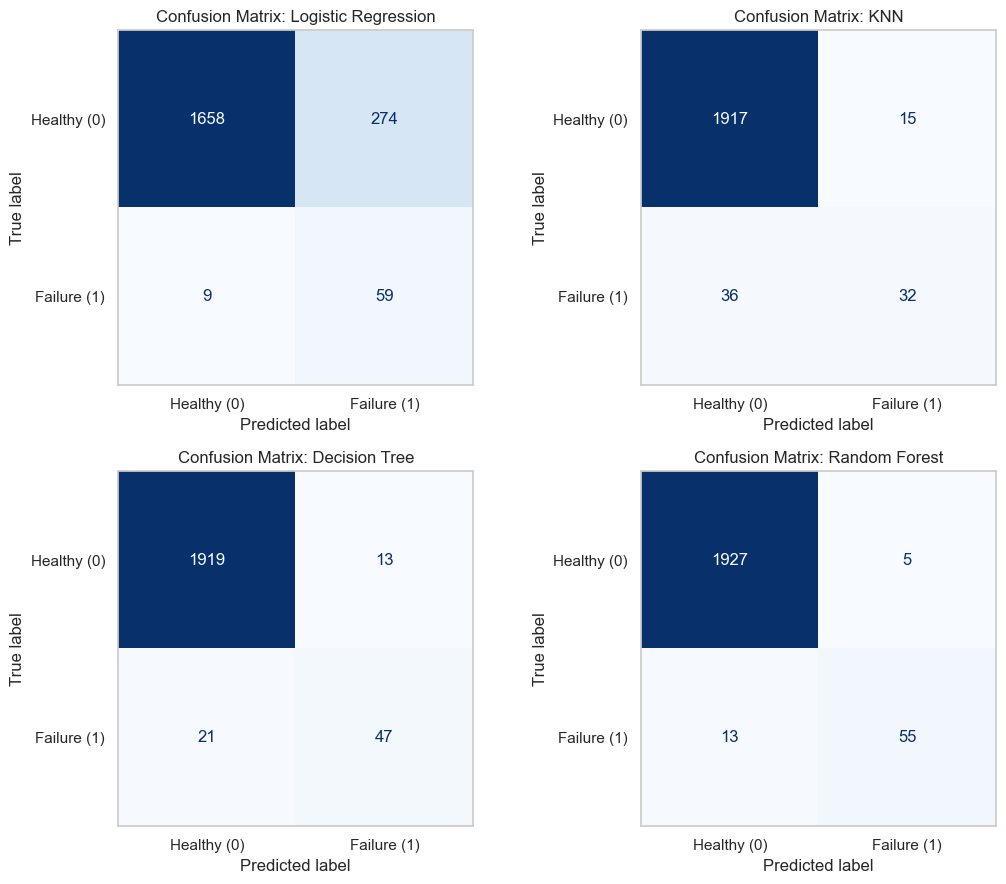

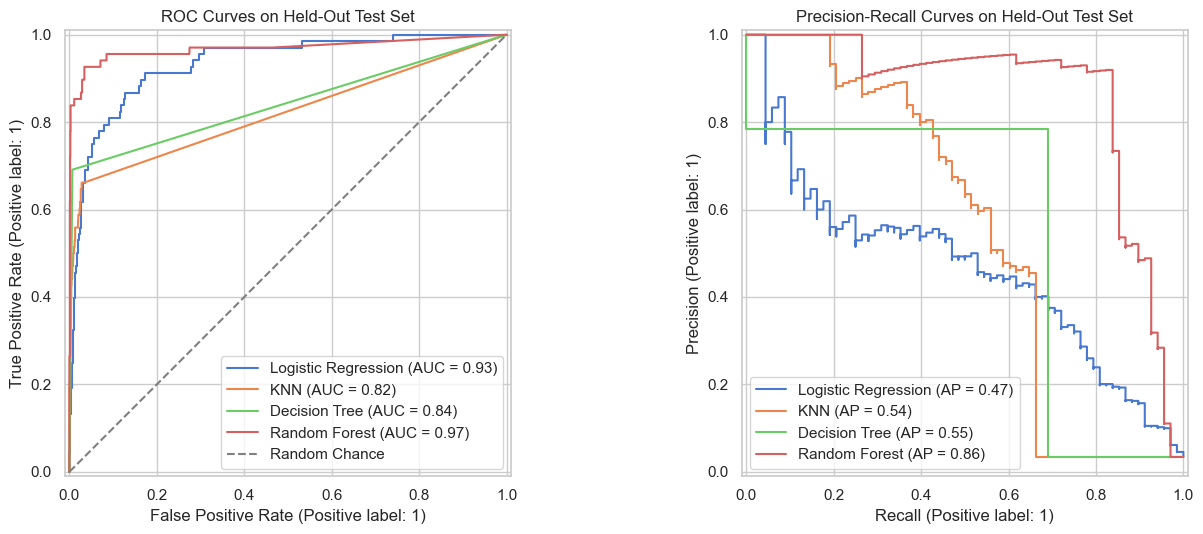

In [22]:
# Plot Confusion Matrices (for the 4 Tuned Models) and ROC + Precision-Recall Curves
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

# 1. Confusion Matrices for the 4 tuned classifiers
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for i, (name, model) in enumerate(tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["Healthy (0)", "Failure (1)"],
        cmap="Blues",
        ax=axes[i],
        colorbar=False
    )
    axes[i].set_title(f"Confusion Matrix: {name}")
    axes[i].grid(False)

plt.tight_layout()
plt.savefig("../outputs/figures/06_confusion_matrices.png", dpi=300)
plt.show()

# 2. ROC Curves and Precision-Recall Curves side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Chance")
axes[0].set_title("ROC Curves on Held-Out Test Set")
axes[0].legend(loc="lower right")

axes[1].set_title("Precision-Recall Curves on Held-Out Test Set")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig("../outputs/figures/07_roc_and_pr_curves.png", dpi=300)
plt.show()

--- Model Interpretation: Random Forest Gini Importance vs Logistic Regression Coefficients ---


,Feature,RF_Gini_Importance,LR_Standardized_Coef,LR_Odds_Ratio_exp(b)
2,Rotational speed [rpm],0.2168,2.3122,10.0967
4,Tool wear [min],0.2064,0.9639,2.6220
6,power,0.2017,-3.9077,0.0201
3,Torque [Nm],0.1964,6.8557,949.2956
5,temp_diff,0.0868,-0.6531,0.5204
0,Air temperature [K],0.0443,0.2429,1.2749
1,Process temperature [K],0.0333,-0.1136,0.8927
8,Type_L,0.0069,-0.1980,0.8203
9,Type_M,0.0050,-0.5503,0.5768
7,Type_H,0.0023,-0.5288,0.5893


C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\2940654742.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\prabu\AppData\Local\Temp\ipykernel_6868\2940654742.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


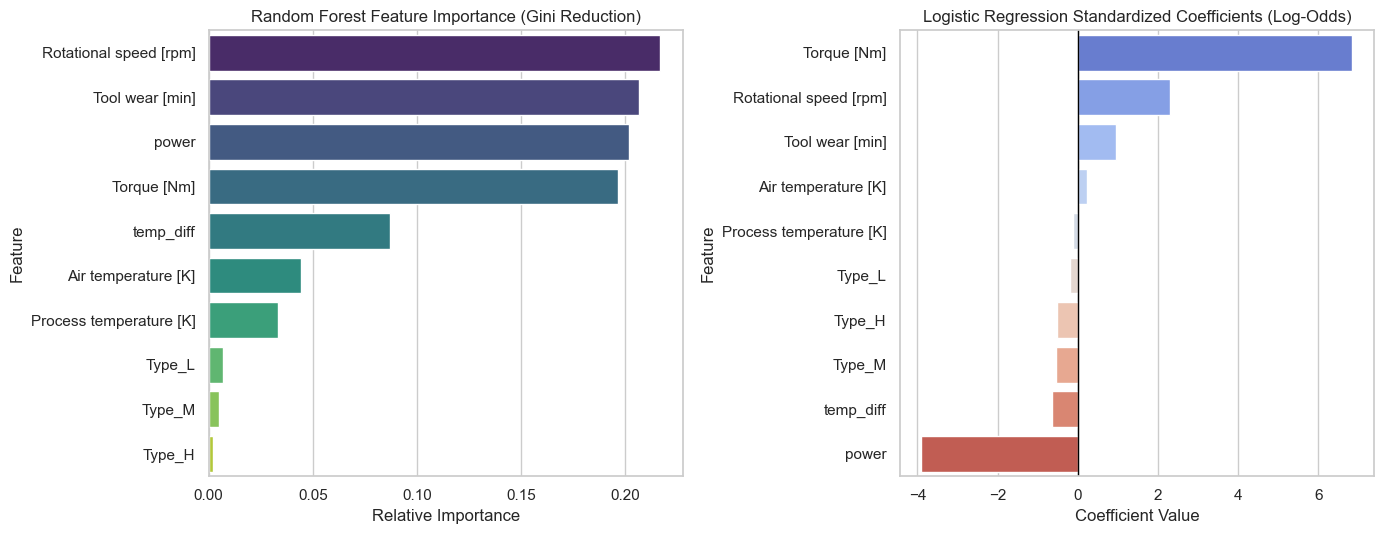

--- Threshold Adjustment Trade-off on Random Forest (Test Set) ---


,Threshold,Recall (Caught %),Precision,F1_Score,TP (Caught),FN (Missed),FP (False Alarms)
0,0.25,0.8529,0.5472,0.6667,58,10,48
1,0.35,0.8382,0.7600,0.7972,57,11,18
2,0.50,0.8088,0.9167,0.8594,55,13,5
3,0.65,0.7206,0.9423,0.8167,49,19,3


In [23]:
# Extract Feature Names, Random Forest Importances, Logistic Regression Coefficients, and Threshold Example
rf_best = tuned_models["Random Forest"]
lr_best = tuned_models["Logistic Regression"]

# Extract transformed feature names from ColumnTransformer
ohe_feature_names = list(
    rf_best.named_steps["prep"]
    .named_transformers_["cat"]
    .named_steps["ohe"]
    .get_feature_names_out(cat_cols)
)
all_feature_names = num_cols_all + ohe_feature_names

# 1. Random Forest Feature Importances
rf_importances = rf_best.named_steps["clf"].feature_importances_
# 2. Logistic Regression Coefficients
lr_coeffs = lr_best.named_steps["clf"].coef_[0]

interp_df = pd.DataFrame({
    "Feature": all_feature_names,
    "RF_Gini_Importance": np.round(rf_importances, 4),
    "LR_Standardized_Coef": np.round(lr_coeffs, 4),
    "LR_Odds_Ratio_exp(b)": np.round(np.exp(lr_coeffs), 4)
}).sort_values(by="RF_Gini_Importance", ascending=False)

print("--- Model Interpretation: Random Forest Gini Importance vs Logistic Regression Coefficients ---")
display(interp_df)

# Plot Feature Importance & Coefficients side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(
    data=interp_df,
    x="RF_Gini_Importance",
    y="Feature",
    ax=axes[0],
    palette="viridis"
)
axes[0].set_title("Random Forest Feature Importance (Gini Reduction)")
axes[0].set_xlabel("Relative Importance")

interp_lr_sorted = interp_df.sort_values(by="LR_Standardized_Coef", ascending=False)
sns.barplot(
    data=interp_lr_sorted,
    x="LR_Standardized_Coef",
    y="Feature",
    ax=axes[1],
    palette="coolwarm"
)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Logistic Regression Standardized Coefficients (Log-Odds)")
axes[1].set_xlabel("Coefficient Value")

plt.tight_layout()
plt.savefig("../outputs/figures/08_feature_importance_and_coefs.png", dpi=300)
plt.show()

# 3. Threshold Adjustment Demonstration on Random Forest
rf_probs = rf_best.predict_proba(X_test)[:, 1]
thresh_rows = []
for thresh in [0.25, 0.35, 0.50, 0.65]:
    preds_t = (rf_probs >= thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds_t).ravel()
    thresh_rows.append({
        "Threshold": thresh,
        "Recall (Caught %)": round(recall_score(y_test, preds_t), 4),
        "Precision": round(precision_score(y_test, preds_t, zero_division=0), 4),
        "F1_Score": round(f1_score(y_test, preds_t, zero_division=0), 4),
        "TP (Caught)": int(tp),
        "FN (Missed)": int(fn),
        "FP (False Alarms)": int(fp)
    })

print("--- Threshold Adjustment Trade-off on Random Forest (Test Set) ---")
display(pd.DataFrame(thresh_rows))

In [24]:
# Automatically select the best model by Test_F1 (verified against CV_F1) and save to models/final_model.joblib
import joblib

best_row = test_results_df.loc[test_results_df["Test_F1"].idxmax()]
best_model_name = best_row["Model"]
final_pipeline = all_eval_models[best_model_name]

os.makedirs("../models", exist_ok=True)
MODEL_PATH = "../models/final_model.joblib"
joblib.dump(final_pipeline, MODEL_PATH)

print(f"Selected Final Model based on actual results: {best_model_name}")
print(f"Saved fitted pipeline to: {MODEL_PATH}")

# Sanity-check reload to verify the saved pipeline works on raw 6-column input
loaded_pipe = joblib.load(MODEL_PATH)
sample_input = X_test.iloc[[0]]
sample_pred = loaded_pipe.predict(sample_input)[0]
sample_prob = loaded_pipe.predict_proba(sample_input)[0, 1]
print(f"Reload check passed! Sample prediction: {sample_pred} (Failure Probability: {sample_prob:.4f})")

Selected Final Model based on actual results: Random Forest
Saved fitted pipeline to: ../models/final_model.joblib
Reload check passed! Sample prediction: 0 (Failure Probability: 0.1768)
